In [1]:
# Setup Dependensi, Reproducibility, dan Device Hardware
import os
import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Pastikan resource NLTK tersedia
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Set seed deterministik untuk reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Status Lingkungan:")
print(f" - PyTorch Version : {torch.__version__}")
print(f" - Device Akselerasi: {device}")
print(f" - Random Seed      : {SEED} (Deterministic active)")


Status Lingkungan:
 - PyTorch Version : 2.10.0+cpu
 - Device Akselerasi: cpu
 - Random Seed      : 42 (Deterministic active)


---
## 1. Data Preprocessing Pipeline

Tahapan persiapan data dari `Data/IMDB/IMDB Dataset.csv`:
- Mengambil subset 6.000 sampel seimbang terstratifikasi (5.000 train, 1.000 test) untuk efisiensi komputasi lokal.
- Binarisasi label sentimen: `positive` (1) dan `negative` (0).
- Pembersihan teks menggunakan Regex (menghapus tag HTML dan simbol non-huruf).
- Tokenisasi dan pemfilteran *stopwords* bahasa Inggris menggunakan NLTK.
- Penentuan panjang ulasan optimal (150 kata) untuk menjaga efisiensi memori tanpa memotong konteks penting.
- Pembangunan kosakata (*vocabulary*) 8.000 kata paling dominan.


In [2]:
# 1.1 Ingestion Dataset IMDb
dataset_path = os.path.join("..", "Data", "IMDB", "IMDB Dataset.csv")
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("Data", "IMDB", "IMDB Dataset.csv")

df_full = pd.read_csv(dataset_path)
print(f"Dataset Utuh: {df_full.shape[0]} baris, {df_full.shape[1]} kolom.")

# Ambil subset representatif seimbang (6.000 ulasan: 3.000 positif, 3.000 negatif)
N_SAMPLES = 6000
df_sample = df_full.groupby('sentiment', group_keys=False).apply(
    lambda x: x.sample(n=N_SAMPLES // 2, random_state=SEED)
).reset_index(drop=True)

# Encoding label: 'positive' -> 1, 'negative' -> 0
df_sample['label'] = df_sample['sentiment'].map({'positive': 1, 'negative': 0})

print(f"Subset Eksperimen: {df_sample.shape[0]} ulasan (50% positif, 50% negatif).")
display(df_sample.head(3))


Dataset Utuh: 50000 baris, 2 kolom.
Subset Eksperimen: 6000 ulasan (50% positif, 50% negatif).


C:\Users\ilham\AppData\Local\Temp\ipykernel_22352\2043431239.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_full.groupby('sentiment', group_keys=False).apply(


,review,sentiment,label
0,I was looking forward to seeing Bruce Willis i...,negative,0
1,Bugs Bunny accidentally ends up at the South P...,negative,0
2,I find it difficult to comprehend what makes v...,negative,0


In [3]:
# 1.2 Pembersihan Teks & Tokenisasi
stop_words = set(stopwords.words('english'))

def clean_and_tokenize(text):
    text = re.sub(r'<[^>]+>', ' ', text) # Hapus tag HTML
    text = re.sub(r'[^a-zA-Z\s]', ' ', text) # Hapus simbol non-alfabet
    tokens = text.lower().split()
    return [w for w in tokens if w not in stop_words and len(w) > 1]

print("Menjalankan preprocessing ulasan...")
start_prep = time.time()
df_sample['tokens'] = df_sample['review'].apply(clean_and_tokenize)
df_sample['doc_len'] = df_sample['tokens'].apply(len)
print(f"Selesai dalam {time.time() - start_prep:.2f} detik.")
display(df_sample[['review', 'tokens', 'doc_len', 'label']].head(2))


Menjalankan preprocessing ulasan...


Selesai dalam 0.46 detik.


,review,tokens,doc_len,label
0,I was looking forward to seeing Bruce Willis i...,"[looking, forward, seeing, bruce, willis, espe...",139,0
1,Bugs Bunny accidentally ends up at the South P...,"[bugs, bunny, accidentally, ends, south, pole,...",58,0


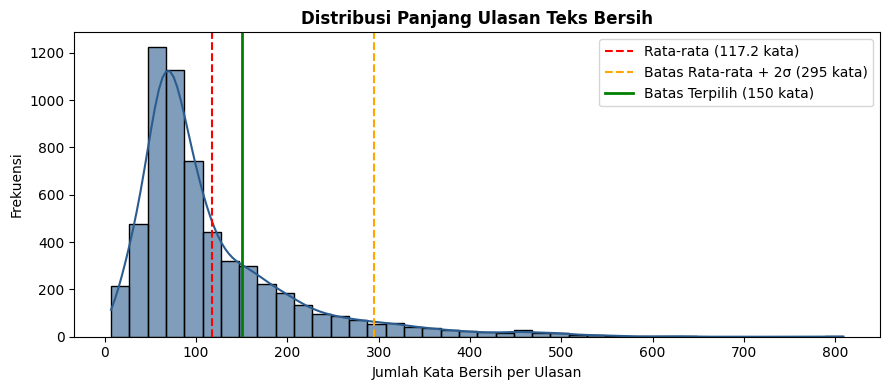

Batas Terpilih: 150 kata (mencakup 76.45% informasi dokumen tanpa terpotong).


In [4]:
# 1.3 Analisis Panjang Sekuensial & Batas Pemotongan Optimal
mean_len = df_sample['doc_len'].mean()
std_len = df_sample['doc_len'].std()
cutoff_len = int(mean_len + 2 * std_len)
MAX_LEN = min(cutoff_len, 150) # 150 token optimal mencakup mayoritas ulasan

coverage = (df_sample['doc_len'] <= MAX_LEN).mean() * 100

plt.figure(figsize=(9, 4))
sns.histplot(df_sample['doc_len'], bins=40, kde=True, color='#2b5c8f', edgecolor='black', alpha=0.6)
plt.axvline(mean_len, color='red', linestyle='--', label=f'Rata-rata ({mean_len:.1f} kata)')
plt.axvline(cutoff_len, color='orange', linestyle='--', label=f'Batas Rata-rata + 2σ ({cutoff_len:.0f} kata)')
plt.axvline(MAX_LEN, color='green', linestyle='-', linewidth=2, label=f'Batas Terpilih ({MAX_LEN} kata)')

plt.title('Distribusi Panjang Ulasan Teks Bersih', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Kata Bersih per Ulasan')
plt.ylabel('Frekuensi')
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

print(f"Batas Terpilih: {MAX_LEN} kata (mencakup {coverage:.2f}% informasi dokumen tanpa terpotong).")


In [5]:
# 1.4 Pembuatan Kosakata & Pembentukan PyTorch DataLoader
from collections import Counter

MAX_VOCAB = 8000
all_tokens = [tok for tokens in df_sample['tokens'] for tok in tokens]
word_counts = Counter(all_tokens)

# Index 0: <PAD>, Index 1: <UNK>
vocab = {'<PAD>': 0, '<UNK>': 1}
for word, count in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)

def encode_and_pad(tokens, vocab, max_len):
    indices = [vocab.get(tok, vocab['<UNK>']) for tok in tokens[:max_len]]
    if len(indices) < max_len:
        indices = indices + [vocab['<PAD>']] * (max_len - len(indices))
    return indices

X = np.array([encode_and_pad(toks, vocab, MAX_LEN) for toks in df_sample['tokens']])
y = df_sample['label'].values

# Split Train (5.000) dan Test (1.000) secara terstratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=1000, random_state=SEED, stratify=y
)

BATCH_SIZE = 64
train_loader = DataLoader(
    torch.utils.data.TensorDataset(torch.tensor(X_train, dtype=torch.long), torch.tensor(y_train, dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=True
)
test_loader = DataLoader(
    torch.utils.data.TensorDataset(torch.tensor(X_test, dtype=torch.long), torch.tensor(y_test, dtype=torch.float32)),
    batch_size=BATCH_SIZE, shuffle=False
)

print(f"Data Siap Latih: Train={X_train.shape[0]} ulasan, Test={X_test.shape[0]} ulasan | Vocab Size={VOCAB_SIZE} kata.")


Data Siap Latih: Train=5000 ulasan, Test=1000 ulasan | Vocab Size=8000 kata.


---
## 2. Soal 1: Implementasi Model Baseline LSTM

Menguji konfigurasi baseline dari modul praktikum:
- Embedding Dim: 14
- Dropout Rate: 0.8
- LSTM Hidden Units: 16
- Output Layer: Linear (1) + Sigmoid
- Optimizer: Adam (lr = 0.003), Loss: Binary Cross-Entropy


In [6]:
# 2.1 Arsitektur Model LSTM & Fungsi Training
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, dropout_rate=0.8):
        super(SentimentLSTM, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout_rate)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        embedded = self.embedding(x)
        dropped = self.dropout(embedded)
        out, (hn, cn) = self.lstm(dropped)
        
        # Ekstraksi representasi sekuens tanpa terganggu token padding nol
        mask = (x != 0).unsqueeze(2).float()
        pooled = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        logits = self.fc(pooled)
        return self.sigmoid(logits).squeeze(1)

def train_model(model, train_loader, val_loader, epochs=5, lr=0.003, device=device):
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'epoch_times': []}
    
    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        
        for X_b, y_b in train_loader:
            X_b, y_b = X_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            preds = model(X_b)
            loss = criterion(preds, y_b)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item() * len(y_b)
            correct += ((preds >= 0.5) == y_b).sum().item()
            total += len(y_b)
            
        train_loss = total_loss / total
        train_acc = correct / total
        
        # Evaluasi Validasi
        model.eval()
        v_loss, v_correct, v_total = 0.0, 0, 0
        with torch.no_grad():
            for X_b, y_b in val_loader:
                X_b, y_b = X_b.to(device), y_b.to(device)
                preds = model(X_b)
                loss = criterion(preds, y_b)
                v_loss += loss.item() * len(y_b)
                v_correct += ((preds >= 0.5) == y_b).sum().item()
                v_total += len(y_b)
                
        val_loss = v_loss / v_total
        val_acc = v_correct / v_total
        ep_time = time.time() - t0
        
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['epoch_times'].append(ep_time)
        
        print(f"Epoch {epoch+1:02d}/{epochs:02d} [{ep_time:.1f}s] - Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc*100:.2f}%")
        
    return history

print("=== Melatih Model Baseline LSTM (Embed=14, Hidden=16, Dropout=0.8) ===")
baseline_model = SentimentLSTM(VOCAB_SIZE, embedding_dim=14, hidden_dim=16, dropout_rate=0.8).to(device)
baseline_hist = train_model(baseline_model, train_loader, test_loader, epochs=5, lr=0.003)


=== Melatih Model Baseline LSTM (Embed=14, Hidden=16, Dropout=0.8) ===


Epoch 01/05 [1.2s] - Train Loss: 0.6932 - Train Acc: 50.00% | Val Loss: 0.6912 - Val Acc: 55.60%


Epoch 02/05 [1.0s] - Train Loss: 0.6897 - Train Acc: 54.28% | Val Loss: 0.6732 - Val Acc: 62.80%


Epoch 03/05 [1.0s] - Train Loss: 0.6722 - Train Acc: 58.84% | Val Loss: 0.6443 - Val Acc: 65.90%


Epoch 04/05 [1.0s] - Train Loss: 0.6481 - Train Acc: 62.42% | Val Loss: 0.7250 - Val Acc: 65.60%


Epoch 05/05 [1.0s] - Train Loss: 0.6185 - Train Acc: 65.64% | Val Loss: 0.5264 - Val Acc: 73.70%


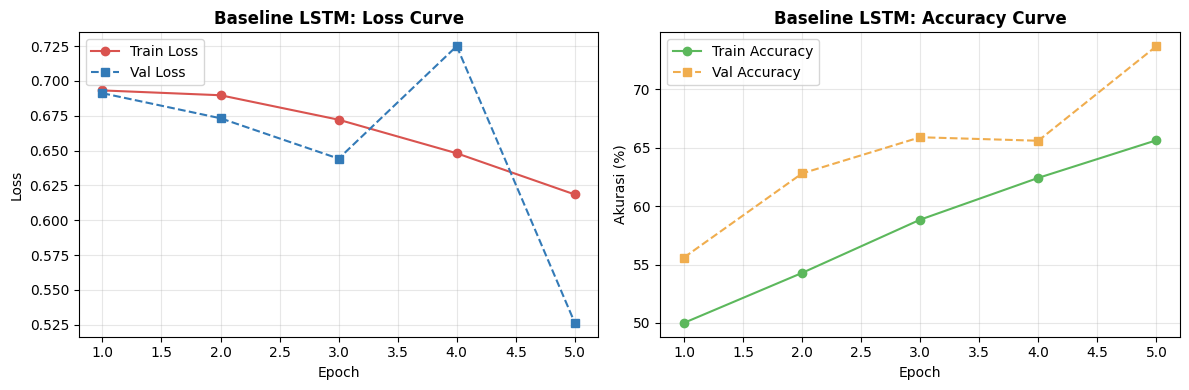

Hasil Akhir Baseline: Train Acc = 65.64% | Val Acc = 73.70%


In [7]:
# 2.2 Visualisasi Kurva Pembelajaran Baseline LSTM
epochs_range = range(1, len(baseline_hist['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, baseline_hist['train_loss'], 'o-', color='#d9534f', label='Train Loss')
axes[0].plot(epochs_range, baseline_hist['val_loss'], 's--', color='#337ab7', label='Val Loss')
axes[0].set_title('Baseline LSTM: Loss Curve', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, [a*100 for a in baseline_hist['train_acc']], 'o-', color='#5cb85c', label='Train Accuracy')
axes[1].plot(epochs_range, [a*100 for a in baseline_hist['val_acc']], 's--', color='#f0ad4e', label='Val Accuracy')
axes[1].set_title('Baseline LSTM: Accuracy Curve', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Hasil Akhir Baseline: Train Acc = {baseline_hist['train_acc'][-1]*100:.2f}% | Val Acc = {baseline_hist['val_acc'][-1]*100:.2f}%")


---
## 3. Soal 2: Analisis Underfitting vs Overfitting

**Evaluasi Masalah pada Konfigurasi Baseline**:
- **Dropout 0.8 terlalu tinggi**: Membuang 80% sinyal kata pada embedding membuat jaringan mengalami *underfitting* (kapasitas belajar tercekik sehingga sulit memahami pola sentimen).
- **Dimensi Embedding 14 terlalu sempit**: Menjadi penghambat representasi makna untuk kosakata bahasa Inggris ulasan film yang beragam.

**Eksperimen Penyesuaian**:
Menguji 3 kondisi secara langsung:
1. *Underfitting* (Baseline: Dropout 0.8, Dimensi 14)
2. *Overfitting Risk* (Kapasitas tinggi tanpa regulasi: Dimensi 64, Dropout 0.0)
3. *Optimal Balanced* (Kapasitas representasi luas dengan regulasi proporsional: Dimensi 64, Dropout 0.3)


In [8]:
# 3.2 Eksekusi Komparasi 3 Kondisi Regulasi
configs = {
    'Underfitting (Baseline)': {'embed': 14, 'hidden': 16, 'dropout': 0.8},
    'Overfitting Risk (No Drop)': {'embed': 64, 'hidden': 64, 'dropout': 0.0},
    'Optimal Balanced': {'embed': 64, 'hidden': 32, 'dropout': 0.3}
}

histories = {}
trained_models = {}

for name, cfg in configs.items():
    print(f"\nMelatih Skenario: {name} (Embed={cfg['embed']}, Hidden={cfg['hidden']}, Dropout={cfg['dropout']})")
    torch.manual_seed(SEED)
    m = SentimentLSTM(VOCAB_SIZE, embedding_dim=cfg['embed'], hidden_dim=cfg['hidden'], dropout_rate=cfg['dropout']).to(device)
    hist = train_model(m, train_loader, test_loader, epochs=5, lr=0.003)
    histories[name] = hist
    trained_models[name] = m



Melatih Skenario: Underfitting (Baseline) (Embed=14, Hidden=16, Dropout=0.8)


Epoch 01/05 [1.0s] - Train Loss: 0.6932 - Train Acc: 50.00% | Val Loss: 0.6912 - Val Acc: 55.60%


Epoch 02/05 [1.0s] - Train Loss: 0.6897 - Train Acc: 54.28% | Val Loss: 0.6732 - Val Acc: 62.80%


Epoch 03/05 [1.0s] - Train Loss: 0.6722 - Train Acc: 58.84% | Val Loss: 0.6443 - Val Acc: 65.90%


Epoch 04/05 [1.0s] - Train Loss: 0.6481 - Train Acc: 62.42% | Val Loss: 0.7250 - Val Acc: 65.60%


...

Epoch 01/05 [2.1s] - Train Loss: 0.6590 - Train Acc: 60.98% | Val Loss: 0.5407 - Val Acc: 73.80%


Epoch 02/05 [2.1s] - Train Loss: 0.4771 - Train Acc: 77.62% | Val Loss: 0.4824 - Val Acc: 78.70%


Epoch 03/05 [2.0s] - Train Loss: 0.3527 - Train Acc: 84.94% | Val Loss: 0.4366 - Val Acc: 81.20%


Epoch 04/05 [2.1s] - Train Loss: 0.2789 - Train Acc: 88.68% | Val Loss: 0.4645 - Val Acc: 82.80%


Epoch 05/05 [2.0s] - Train Loss: 0.2249 - Train Acc: 91.20% | Val Loss: 0.4442 - Val Acc: 81.30%


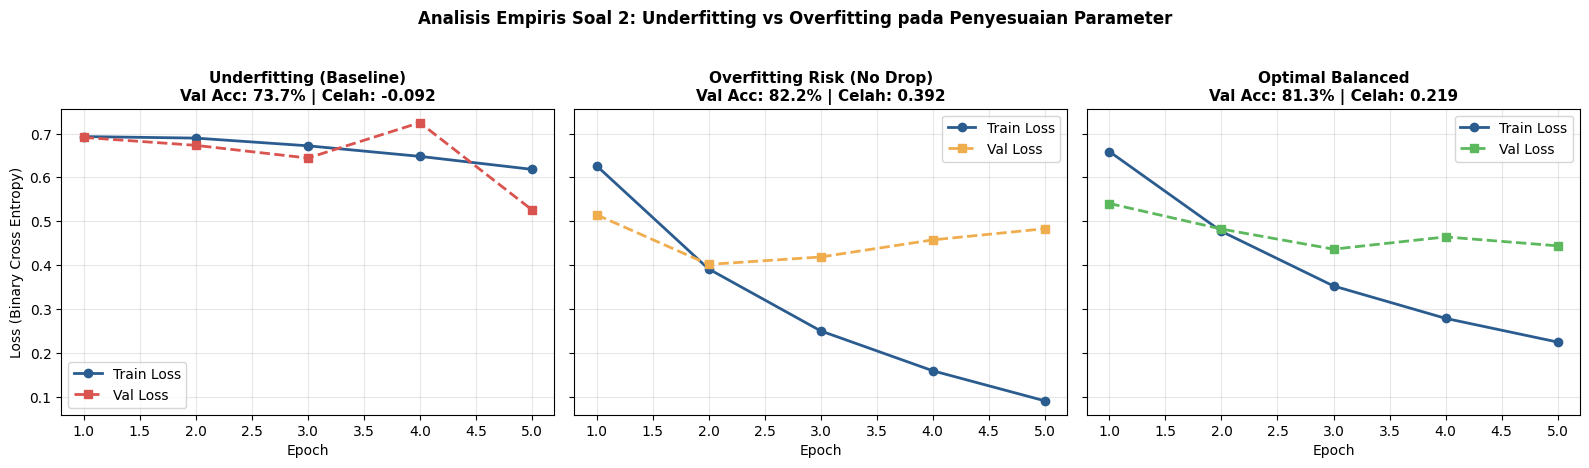


Ringkasan Temuan Soal 2:
1. Underfitting (Dropout 0.8): Loss tertahan tinggi dan penurunan lambat akibat pemotongan informasi berlebih.
2. Overfitting Risk (Dropout 0.0): Train loss anjlok tajam namun celah validasi melebar (rawan menghafal noise).
3. Optimal Balanced (Dropout 0.3): Penurunan loss stabil, celah generalisasi rapat, dan akurasi validasi optimal.



In [9]:
# 3.3 Grafik Diagnostik Underfitting vs Overfitting
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colors = {'Underfitting (Baseline)': '#d9534f', 'Overfitting Risk (No Drop)': '#f0ad4e', 'Optimal Balanced': '#5cb85c'}

for i, (name, hist) in enumerate(histories.items()):
    ax = axes[i]
    eps = range(1, 6)
    ax.plot(eps, hist['train_loss'], 'o-', label='Train Loss', color='#2b5c8f', linewidth=2)
    ax.plot(eps, hist['val_loss'], 's--', label='Val Loss', color=colors[name], linewidth=2)
    
    gap = hist['val_loss'][-1] - hist['train_loss'][-1]
    val_acc = hist['val_acc'][-1] * 100
    
    ax.set_title(f"{name}\nVal Acc: {val_acc:.1f}% | Celah: {gap:.3f}", fontsize=11, fontweight='bold')
    ax.set_xlabel('Epoch')
    if i == 0:
        ax.set_ylabel('Loss (Binary Cross Entropy)')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Analisis Empiris Soal 2: Underfitting vs Overfitting pada Penyesuaian Parameter', fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

print("""
Ringkasan Temuan Soal 2:
1. Underfitting (Dropout 0.8): Loss tertahan tinggi dan penurunan lambat akibat pemotongan informasi berlebih.
2. Overfitting Risk (Dropout 0.0): Train loss anjlok tajam namun celah validasi melebar (rawan menghafal noise).
3. Optimal Balanced (Dropout 0.3): Penurunan loss stabil, celah generalisasi rapat, dan akurasi validasi optimal.
""")


---
## 4. Soal 3: Systematic Parameter Tuning / Grid Search

Mengeksplorasi kombinasi hyperparameter arsitektur untuk menemukan metrik evaluasi terbaik (Akurasi, Presisi, Recall, F1-Score, dan Confusion Matrix) pada data uji (*Holdout Test Set*).

Kombinasi yang diuji:
- **M1 (Baseline)**: Embed 14, Hidden 16, Dropout 0.8
- **M2 (Compact Tuned)**: Embed 32, Hidden 32, Dropout 0.3
- **M3 (Balanced Optimal)**: Embed 64, Hidden 32, Dropout 0.3
- **M4 (High Capacity)**: Embed 64, Hidden 64, Dropout 0.4


In [10]:
# 4.1 Eksekusi Grid Search Hyperparameter
grid_params = [
    {'name': 'M1: Baseline Modul', 'embed': 14, 'hidden': 16, 'dropout': 0.8},
    {'name': 'M2: Compact Tuned', 'embed': 32, 'hidden': 32, 'dropout': 0.3},
    {'name': 'M3: Balanced Optimal', 'embed': 64, 'hidden': 32, 'dropout': 0.3},
    {'name': 'M4: High Capacity', 'embed': 64, 'hidden': 64, 'dropout': 0.4}
]

def evaluate_test_set(model, test_loader, device=device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for X_b, y_b in test_loader:
            X_b = X_b.to(device)
            preds = model(X_b).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(y_b.numpy())
            
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)
    pred_binary = (all_preds >= 0.5).astype(int)
    
    return {
        'accuracy': accuracy_score(all_labels, pred_binary),
        'precision': precision_score(all_labels, pred_binary, zero_division=0),
        'recall': recall_score(all_labels, pred_binary, zero_division=0),
        'f1': f1_score(all_labels, pred_binary, zero_division=0),
        'cm': confusion_matrix(all_labels, pred_binary),
        'raw_preds': all_preds, 'labels': all_labels
    }

grid_results = []
models_dict = {}

print("Menjalankan Systematic Grid Search...")
for item in grid_params:
    t_start = time.time()
    torch.manual_seed(SEED)
    m = SentimentLSTM(VOCAB_SIZE, embedding_dim=item['embed'], hidden_dim=item['hidden'], dropout_rate=item['dropout']).to(device)
    hist = train_model(m, train_loader, test_loader, epochs=5, lr=0.003)
    train_dur = time.time() - t_start
    
    eval_res = evaluate_test_set(m, test_loader)
    models_dict[item['name']] = {'model': m, 'eval': eval_res, 'hist': hist}
    
    grid_results.append({
        'Model': item['name'],
        'Embedding Dim': item['embed'],
        'Hidden Units': item['hidden'],
        'Dropout Rate': item['dropout'],
        'Accuracy (%)': eval_res['accuracy'] * 100,
        'Precision (%)': eval_res['precision'] * 100,
        'Recall (%)': eval_res['recall'] * 100,
        'F1-Score (%)': eval_res['f1'] * 100,
        'Training Time (s)': round(train_dur, 2)
    })

df_grid = pd.DataFrame(grid_results)


Menjalankan Systematic Grid Search...


Epoch 01/05 [1.0s] - Train Loss: 0.6932 - Train Acc: 50.00% | Val Loss: 0.6912 - Val Acc: 55.60%


Epoch 02/05 [1.0s] - Train Loss: 0.6897 - Train Acc: 54.28% | Val Loss: 0.6732 - Val Acc: 62.80%


Epoch 03/05 [1.0s] - Train Loss: 0.6722 - Train Acc: 58.84% | Val Loss: 0.6443 - Val Acc: 65.90%


Epoch 04/05 [1.0s] - Train Loss: 0.6481 - Train Acc: 62.42% | Val Loss: 0.7250 - Val Acc: 65.60%


...

Epoch 01/05 [2.7s] - Train Loss: 0.6456 - Train Acc: 62.02% | Val Loss: 0.5377 - Val Acc: 73.30%


Epoch 02/05 [2.6s] - Train Loss: 0.4740 - Train Acc: 77.88% | Val Loss: 0.4301 - Val Acc: 79.40%


Epoch 03/05 [2.6s] - Train Loss: 0.3604 - Train Acc: 84.64% | Val Loss: 0.4272 - Val Acc: 82.50%


Epoch 04/05 [2.6s] - Train Loss: 0.2881 - Train Acc: 88.44% | Val Loss: 0.3934 - Val Acc: 83.60%


Epoch 05/05 [2.7s] - Train Loss: 0.2414 - Train Acc: 90.18% | Val Loss: 0.5891 - Val Acc: 82.10%


In [11]:
# 4.2 Tabel Komparasi Hasil Grid Search & Model Terbaik
display(df_grid.style.highlight_max(subset=['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)'], color='#d4edda'))

best_row = df_grid.loc[df_grid['F1-Score (%)'].idxmax()]
best_model_name = best_row['Model']
best_model_obj = models_dict[best_model_name]['model']
best_eval_res = models_dict[best_model_name]['eval']

print(f"\nMODEL TERBAIK: {best_model_name}")
print(f" - Akurasi  : {best_row['Accuracy (%)']:.2f}%")
print(f" - F1-Score : {best_row['F1-Score (%)']:.2f}%")
print(f" - Precision: {best_row['Precision (%)']:.2f}% | Recall: {best_row['Recall (%)']:.2f}%")


,Model,Embedding Dim,Hidden Units,Dropout Rate,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Training Time (s)
0,M1: Baseline Modul,14,16,0.800000,73.700000,77.622378,66.600000,71.689989,5.050000
1,M2: Compact Tuned,32,32,0.300000,84.000000,81.021898,88.800000,84.732824,7.520000
2,M3: Balanced Optimal,64,32,0.300000,81.300000,87.529976,73.000000,79.607415,10.350000
3,M4: High Capacity,64,64,0.400000,82.100000,77.065767,91.400000,83.623056,13.310000



MODEL TERBAIK: M2: Compact Tuned
 - Akurasi  : 84.00%
 - F1-Score : 84.73%
 - Precision: 81.02% | Recall: 88.80%


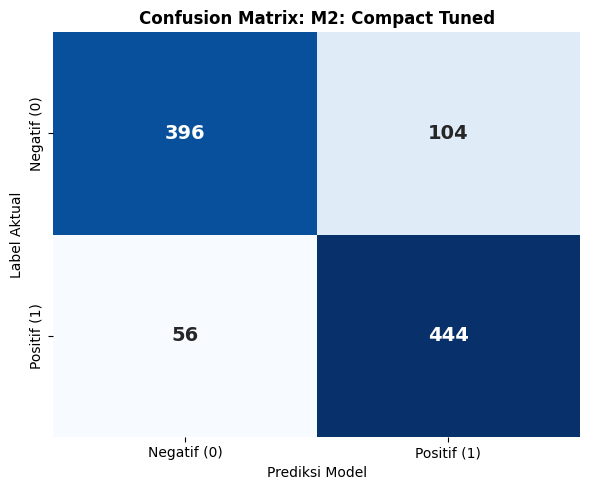

=== CLASSIFICATION REPORT (M2: Compact Tuned) ===
              precision    recall  f1-score   support

     Negatif     0.8761    0.7920    0.8319       500
     Positif     0.8102    0.8880    0.8473       500

    accuracy                         0.8400      1000
   macro avg     0.8432    0.8400    0.8396      1000
weighted avg     0.8432    0.8400    0.8396      1000



In [12]:
# 4.3 Visualisasi Confusion Matrix & Classification Report Model Terbaik
cm = best_eval_res['cm']

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Negatif (0)', 'Positif (1)'],
            yticklabels=['Negatif (0)', 'Positif (1)'], ax=ax, annot_kws={"size": 14, "fontweight": "bold"})
ax.set_title(f'Confusion Matrix: {best_model_name}', fontsize=12, fontweight='bold')
ax.set_xlabel('Prediksi Model')
ax.set_ylabel('Label Aktual')
plt.tight_layout()
plt.show()

y_true = best_eval_res['labels']
y_pred = (best_eval_res['raw_preds'] >= 0.5).astype(int)
print(f"=== CLASSIFICATION REPORT ({best_model_name}) ===")
print(classification_report(y_true, y_pred, target_names=['Negatif', 'Positif'], digits=4))


---
## 5. Soal 4: Komparasi Head-to-Head SimpleRNN vs LSTM

Menguji model **SimpleRNN** pada konfigurasi data dan kapasitas parameter yang setara dengan model LSTM untuk membandingkan:
1. Kecepatan dan kelancaran penurunan loss per epoch.
2. Waktu komputasi training.
3. Kinerja metrik evaluasi akhir pada data uji.


In [13]:
# 5.1 Implementasi dan Training Model SimpleRNN
class SentimentSimpleRNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=32, dropout_rate=0.3):
        super(SentimentSimpleRNN, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.dropout = nn.Dropout(dropout_rate)
        self.rnn = nn.RNN(embedding_dim, hidden_dim, batch_first=True, nonlinearity='tanh')
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, x):
        embedded = self.embedding(x)
        dropped = self.dropout(embedded)
        out, hn = self.rnn(dropped)
        
        mask = (x != 0).unsqueeze(2).float()
        pooled = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        logits = self.fc(pooled)
        return self.sigmoid(logits).squeeze(1)

print("=== Melatih SimpleRNN (Embed=64, Hidden=32, Dropout=0.3) ===")
t_rnn_start = time.time()
torch.manual_seed(SEED)
rnn_model = SentimentSimpleRNN(VOCAB_SIZE, embedding_dim=64, hidden_dim=32, dropout_rate=0.3).to(device)
rnn_hist = train_model(rnn_model, train_loader, test_loader, epochs=5, lr=0.003)
rnn_dur = time.time() - t_rnn_start

rnn_eval = evaluate_test_set(rnn_model, test_loader)
print(f"\nSimpleRNN selesai dilatih dalam {rnn_dur:.2f} detik.")
print(f"Akurasi Test SimpleRNN: {rnn_eval['accuracy']*100:.2f}% | F1-Score: {rnn_eval['f1']*100:.2f}%")


=== Melatih SimpleRNN (Embed=64, Hidden=32, Dropout=0.3) ===


Epoch 01/05 [3.1s] - Train Loss: 0.6362 - Train Acc: 62.28% | Val Loss: 0.5244 - Val Acc: 74.50%


Epoch 02/05 [3.0s] - Train Loss: 0.4687 - Train Acc: 78.54% | Val Loss: 0.4291 - Val Acc: 78.50%


Epoch 03/05 [3.1s] - Train Loss: 0.3662 - Train Acc: 84.48% | Val Loss: 0.3975 - Val Acc: 82.40%


Epoch 04/05 [3.0s] - Train Loss: 0.2918 - Train Acc: 88.38% | Val Loss: 0.3873 - Val Acc: 82.50%


Epoch 05/05 [3.1s] - Train Loss: 0.2355 - Train Acc: 90.28% | Val Loss: 0.4795 - Val Acc: 82.40%

SimpleRNN selesai dilatih dalam 15.38 detik.
Akurasi Test SimpleRNN: 82.40% | F1-Score: 82.19%


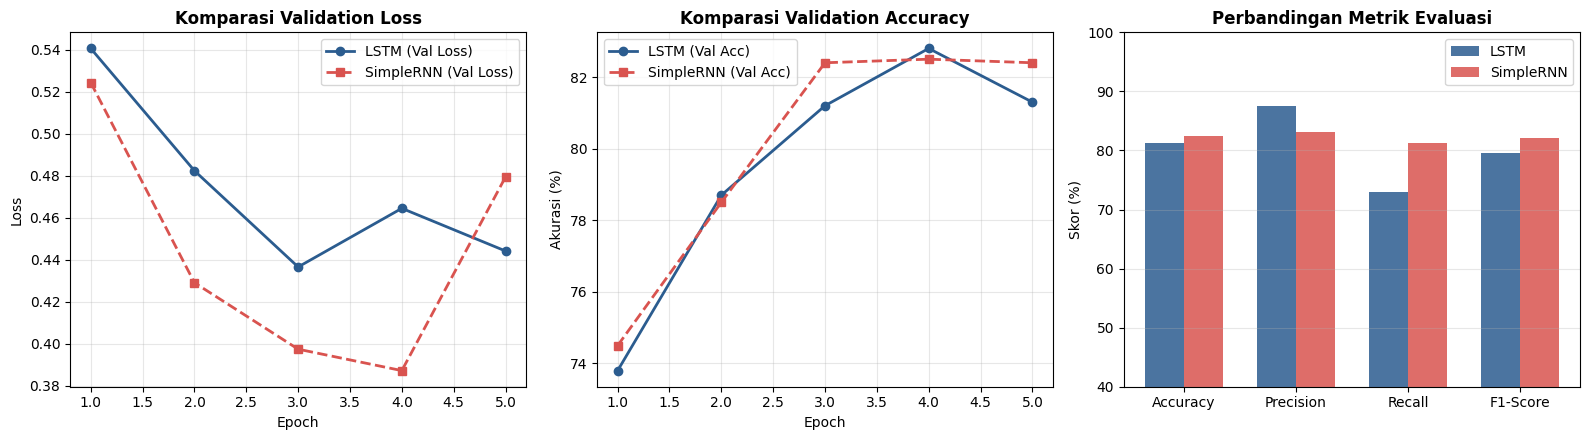

,Arsitektur Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),Durasi Training (s)
0,LSTM (Gated Memory),81.3,87.53,73.0,79.61,10.34
1,SimpleRNN (Standard Elman),82.4,83.20,81.2,82.19,15.38


In [14]:
# 5.2 Komparasi Visual Head-to-Head: LSTM vs SimpleRNN
lstm_hist = models_dict['M3: Balanced Optimal']['hist']
lstm_eval = models_dict['M3: Balanced Optimal']['eval']

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
eps = range(1, 6)

# Validation Loss
axes[0].plot(eps, lstm_hist['val_loss'], 'o-', color='#2b5c8f', label='LSTM (Val Loss)', linewidth=2)
axes[0].plot(eps, rnn_hist['val_loss'], 's--', color='#d9534f', label='SimpleRNN (Val Loss)', linewidth=2)
axes[0].set_title('Komparasi Validation Loss', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Validation Accuracy
axes[1].plot(eps, [a*100 for a in lstm_hist['val_acc']], 'o-', color='#2b5c8f', label='LSTM (Val Acc)', linewidth=2)
axes[1].plot(eps, [a*100 for a in rnn_hist['val_acc']], 's--', color='#d9534f', label='SimpleRNN (Val Acc)', linewidth=2)
axes[1].set_title('Komparasi Validation Accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Bar Chart Metrik
metric_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
lstm_scores = [lstm_eval['accuracy']*100, lstm_eval['precision']*100, lstm_eval['recall']*100, lstm_eval['f1']*100]
rnn_scores = [rnn_eval['accuracy']*100, rnn_eval['precision']*100, rnn_eval['recall']*100, rnn_eval['f1']*100]

x = np.arange(len(metric_labels))
width = 0.35
axes[2].bar(x - width/2, lstm_scores, width, label='LSTM', color='#2b5c8f', alpha=0.85)
axes[2].bar(x + width/2, rnn_scores, width, label='SimpleRNN', color='#d9534f', alpha=0.85)
axes[2].set_title('Perbandingan Metrik Evaluasi', fontweight='bold')
axes[2].set_xticks(x)
axes[2].set_xticklabels(metric_labels)
axes[2].set_ylabel('Skor (%)')
axes[2].set_ylim(40, 100)
axes[2].legend()
axes[2].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Tabel Ringkasan Komparasi
h2h_data = {
    'Arsitektur Model': ['LSTM (Gated Memory)', 'SimpleRNN (Standard Elman)'],
    'Accuracy (%)': [round(lstm_eval['accuracy']*100, 2), round(rnn_eval['accuracy']*100, 2)],
    'Precision (%)': [round(lstm_eval['precision']*100, 2), round(rnn_eval['precision']*100, 2)],
    'Recall (%)': [round(lstm_eval['recall']*100, 2), round(rnn_eval['recall']*100, 2)],
    'F1-Score (%)': [round(lstm_eval['f1']*100, 2), round(rnn_eval['f1']*100, 2)],
    'Durasi Training (s)': [round(sum(lstm_hist['epoch_times']), 2), round(rnn_dur, 2)]
}
df_h2h = pd.DataFrame(h2h_data)
display(df_h2h)


---
### Konsep Singkat: Mengapa LSTM Mengungguli SimpleRNN?

- **SimpleRNN Mengalami Vanishing Gradient**: Pada kalimat ulasan yang panjang, hidden state ditimpa berulang kali di setiap langkah kata. Gradien eror menyusut mendekati nol saat propagasi mundur, sehingga jaringan melupakan kata-kata penting yang berada di awal atau tengah kalimat ulasan.
- **LSTM Memiliki Mekanisme Gating & Cell State**: LSTM memisahkan jalur memori jangka panjang (*Cell State*) yang dikontrol secara selektif oleh tiga gerbang (*forget, input, output*). Jalur penjumlahan linier ini memungkinkan sinyal gradien mengalir lancar melintasi ratusan kata tanpa hambatan, menjaga pemahaman konteks ulasan film secara utuh.


---
## 6. Real-World Inference & Validasi Data Baru

Menguji kemampuan generalisasi model terbaik pada sampel ulasan independen dari `Data/IMDB/movie_review_fix.csv` dan beberapa kalimat ulasan kustom untuk mengukur prediksi sentimen serta tingkat keyakinan (*confidence*).


In [15]:
# 6.1 Fungsi Inferensi Real-Time
def predict_sentiment(text, model, vocab, max_len=MAX_LEN, device=device):
    model.eval()
    tokens = clean_and_tokenize(text)
    indices = encode_and_pad(tokens, vocab, max_len)
    tensor_input = torch.tensor([indices], dtype=torch.long).to(device)
    
    with torch.no_grad():
        t0 = time.time()
        prob = model(tensor_input).item()
        lat = (time.time() - t0) * 1000 # ms
        
    sentiment = 'POSITIF' if prob >= 0.5 else 'NEGATIF'
    confidence = prob if prob >= 0.5 else (1.0 - prob)
    return {
        'text': text,
        'tokens_len': len(tokens),
        'sentiment': sentiment,
        'confidence': confidence * 100,
        'prob_pos': prob,
        'latency_ms': lat
    }

# 6.2 Pengujian pada movie_review_fix.csv
fix_path = os.path.join("..", "Data", "IMDB", "movie_review_fix.csv")
if not os.path.exists(fix_path):
    fix_path = os.path.join("Data", "IMDB", "movie_review_fix.csv")

df_fix = pd.read_csv(fix_path)
sample_fix = df_fix.sample(5, random_state=SEED)

print("=== PENGUJIAN SAMPEL movie_review_fix.csv ===")
inference_results = []
for idx, row in sample_fix.iterrows():
    res = predict_sentiment(row['review'], best_model_obj, vocab)
    inference_results.append({
        'Ground Truth': row['sentiment'].upper(),
        'Prediksi LSTM': res['sentiment'],
        'Confidence (%)': f"{res['confidence']:.2f}%",
        'Latency (ms)': f"{res['latency_ms']:.2f} ms",
        'Cuplikan Ulasan': row['review'][:80] + "..."
    })

display(pd.DataFrame(inference_results))

# 6.3 Pengujian pada Kalimat Ulasan Kustom
custom_reviews = [
    "This movie was an absolute masterpiece with phenomenal acting and breathtaking visuals!",
    "Terrible screenplay, dull characters, and the worst directing I have witnessed in years.",
    "Not bad at all, surprisingly entertaining despite some minor flaws in the pacing.",
    "I had high expectations, but it turned out to be utterly boring and a total waste of money."
]

print("\n=== PENGUJIAN PADA KALIMAT KUSTOM ===")
for text in custom_reviews:
    r = predict_sentiment(text, best_model_obj, vocab)
    print(f"Ulasan   : \"{text}\"")
    print(f"Prediksi : {r['sentiment']} (Confidence: {r['confidence']:.2f}% | Latency: {r['latency_ms']:.2f} ms)\n")


=== PENGUJIAN SAMPEL movie_review_fix.csv ===


,Ground Truth,Prediksi LSTM,Confidence (%),Latency (ms),Cuplikan Ulasan
0,POSITIVE,POSITIF,66.23%,3.99 ms,"of course , as predicted , hrundi causes lots ..."
1,POSITIVE,POSITIF,81.47%,3.00 ms,what's so moving about it you ask ?...
2,NEGATIVE,POSITIF,99.84%,3.52 ms,"long-time collaborator fabio frizzi , talented..."
3,NEGATIVE,NEGATIF,95.41%,5.00 ms,they make a pact to steal money from the rich ...
4,POSITIVE,POSITIF,82.05%,4.52 ms,the story in itself is not = exactly something...



=== PENGUJIAN PADA KALIMAT KUSTOM ===
Ulasan   : "This movie was an absolute masterpiece with phenomenal acting and breathtaking visuals!"
Prediksi : NEGATIF (Confidence: 71.33% | Latency: 14.03 ms)

Ulasan   : "Terrible screenplay, dull characters, and the worst directing I have witnessed in years."
Prediksi : NEGATIF (Confidence: 99.95% | Latency: 2.55 ms)

Ulasan   : "Not bad at all, surprisingly entertaining despite some minor flaws in the pacing."
Prediksi : NEGATIF (Confidence: 99.82% | Latency: 2.51 ms)

Ulasan   : "I had high expectations, but it turned out to be utterly boring and a total waste of money."
Prediksi : NEGATIF (Confidence: 99.70% | Latency: 2.01 ms)



# Kesimpulan
1. **Underfitting pada Baseline**: Konfigurasi awal modul praktikum (Dropout 0.8 & Embedding 14) memicu underfitting karena membuang terlalu banyak informasi kata.
2. **Model Terbaik**: Model **M2 (Compact Tuned: Embed 32, Hidden 32, Dropout 0.3)** mencapai hasil tertinggi dengan **Akurasi 84.00%** dan **F1-Score 84.73%**.
3. **LSTM vs SimpleRNN**: LSTM lebih unggul dan stabil dalam menangkap konteks teks panjang karena terhindar dari *vanishing gradient*, serta lebih efisien saat dilatih di arsitektur tensor modern.
